# Convolução 2D: Projeto (Sinais e Sistemas, 2ª Unidade)

Baseado no módulo `4_ Convolucion_2.ipynb` do curso.

Roteiro:
1. Convolução 2D: exemplo básico (conta feita à mão e pelo SciPy)
2. Função que filtra uma imagem colorida
3. Kernel de realce (enfoque)
4. Filtro de média, com **kernels cada vez maiores**
5. Detecção de bordas (e bordas verticais/horizontais, o "Taller" do curso)
6. Suavização gaussiana, com **kernels maiores** e comparação com a média
7. Convolução em vídeo (webcam, opcional)

## 1. Convolução 2D: exemplo básico

In [1]:
import numpy as np               # NumPy: matrizes e operações numéricas
import matplotlib.pyplot as plt  # Matplotlib: leitura e exibição das imagens
from scipy import signal         # SciPy: tem a função de convolução 2D (signal.convolve2d)

Uma imagem em tons de cinza é uma **matriz** de números (um número por pixel).
A convolução 2D é a mesma ideia da 1D, só que o kernel é uma **matriz pequena** que desliza nas duas direções:

$$S[i,j] = \sum_{m}\sum_{n} I[m,n]\,K[i-m,\,j-n]$$

O kernel é **refletido** (girado 180°), **desliza** sobre a imagem e, em cada posição,
os produtos dos elementos sobrepostos são **somados**.

In [2]:
Matriz = np.array([[1, 1, 1, 1],   # matriz 4x4: metade de cima com 1 ("claro")
                   [1, 1, 1, 1],
                   [0, 0, 0, 0],   # metade de baixo com 0 ("escuro")
                   [0, 0, 0, 0]])
kernel = np.array([[ 1,  1],       # kernel 2x2: compara a linha de cima
                   [-1, -1]])      # com a linha de baixo (detecta borda horizontal)
print(Matriz)                      # mostra a matriz de entrada

[[1 1 1 1]
 [1 1 1 1]
 [0 0 0 0]
 [0 0 0 0]]


In [3]:
S_full = signal.convolve2d(Matriz, kernel, mode='full')  # convolução completa: (4+2-1) x (4+2-1) = 5x5
S_same = signal.convolve2d(Matriz, kernel, mode='same')  # só o trecho central, do mesmo tamanho da entrada (4x4)
print('full (5x5):')   # título
print(S_full)          # resultado completo
print('same (4x4):')   # título
print(S_same)          # resultado do mesmo tamanho da entrada

full (5x5):
[[ 1  2  2  2  1]
 [ 0  0  0  0  0]
 [-1 -2 -2 -2 -1]
 [ 0  0  0  0  0]
 [ 0  0  0  0  0]]
same (4x4):
[[ 1  2  2  2]
 [ 0  0  0  0]
 [-1 -2 -2 -2]
 [ 0  0  0  0]]


Como ler o resultado (o kernel refletido é `[[-1,-1],[1,1]]`: −1 na linha de cima, +1 na de baixo):

- **Linha 1 = 0:** o kernel está todo dentro da região clara: −1 −1 + 1 + 1 = 0. Região uniforme dá zero.
- **Linha 2 = −2:** o kernel está **exatamente sobre a borda**, com a parte de cima no claro (1) e a de baixo no escuro (0):
  −1·1 −1·1 + 1·0 + 1·0 = −2. Ou seja, **o kernel "acende" onde a imagem muda**.
- **Linha 0 = 2:** é um **efeito de borda**. Acima da matriz não há dados e o SciPy completa com **zeros**,
  então o kernel "vê" uma passagem de escuro (0) para claro (1), com o sinal trocado (+2).
- A **primeira coluna** vale metade (1 e −1) porque ali o kernel fica metade para fora da matriz.

Abaixo, a mesma conta com laços `for`, seguindo a fórmula, para mostrar que a função do SciPy não é mágica:

In [4]:
L, C = Matriz.shape                      # número de linhas e colunas da matriz (4, 4)
kL, kC = kernel.shape                    # número de linhas e colunas do kernel (2, 2)
S_manual = np.zeros((L + kL - 1, C + kC - 1))  # saída completa 5x5 cheia de zeros
for i in range(S_manual.shape[0]):       # percorre cada linha i da saída
    for j in range(S_manual.shape[1]):   # percorre cada coluna j da saída
        for m in range(L):               # percorre cada linha m da matriz
            for n in range(C):           # percorre cada coluna n da matriz
                if 0 <= i - m < kL and 0 <= j - n < kC:            # só soma se o índice do kernel existe
                    S_manual[i, j] += Matriz[m, n] * kernel[i - m, j - n]  # definição da convolução 2D
print(S_manual)                          # deve ser igual ao S_full do SciPy
print('Igual ao SciPy?', np.array_equal(S_manual, S_full))  # confere

[[ 1.  2.  2.  2.  1.]
 [ 0.  0.  0.  0.  0.]
 [-1. -2. -2. -2. -1.]
 [ 0.  0.  0.  0.  0.]
 [ 0.  0.  0.  0.  0.]]
Igual ao SciPy? True


## 2. Filtrando uma imagem colorida

Uma imagem colorida tem **3 matrizes** (canais R, G e B). A função abaixo aplica a convolução
**em cada canal separadamente** e depois junta os três de novo.

- `mode='same'`: a imagem filtrada tem o mesmo tamanho da original.
- `boundary='symm'`: nas bordas, em vez de completar com zeros (o que escureceria a borda),
  o SciPy **espelha** a imagem.
- Os pixels precisam ficar entre 0 e 255, então os valores fora dessa faixa são cortados.

In [5]:
def filtra(imagem, kernel):                       # aplica o kernel numa imagem colorida e devolve o resultado
    canais = []                                   # lista para guardar os 3 canais filtrados
    for d in range(3):                            # d = 0 (vermelho), 1 (verde), 2 (azul)
        temp = signal.convolve2d(imagem[:, :, d], kernel,     # convolução 2D do canal d com o kernel
                                 boundary='symm', mode='same')  # bordas espelhadas, mesmo tamanho
        canais.append(temp)                       # guarda o canal filtrado
    imagem_filt = np.stack(canais, axis=2)        # junta os 3 canais de volta numa imagem (altura x largura x 3)
    imagem_filt = np.clip(imagem_filt, 0, 255)    # corta os valores para a faixa válida 0..255
    return imagem_filt.astype('uint8')            # converte para inteiro de 8 bits (formato de imagem)

def mostra(imagens, titulos):                     # mostra várias imagens lado a lado
    fig, axs = plt.subplots(1, len(imagens), figsize=(4 * len(imagens), 4))  # uma coluna por imagem
    for ax, img, tit in zip(axs, imagens, titulos):  # percorre imagens e títulos juntos
        ax.imshow(img)                            # desenha a imagem
        ax.set_title(tit)                         # título acima da imagem
        ax.axis('off')                            # esconde os eixos
    plt.tight_layout()                            # ajusta os espaços
    plt.show()                                    # exibe a figura

In [6]:
imagem = plt.imread('4.data/tito2.jpg')  # lê a imagem do disco como matriz (altura x largura x 3)
print('Formato da imagem:', imagem.shape)  # (linhas, colunas, canais)
print('Pixel [0,0] (R, G, B):', imagem[0, 0])  # cada pixel são 3 números de 0 a 255

Formato da imagem: (255, 340, 3)
Pixel [0,0] (R, G, B): [104  85  68]


## 3. Realce (enfoque)

O kernel de realce soma **5×** o pixel central e subtrai os 4 vizinhos. A soma dos pesos é 1
(5 − 4 = 1), então regiões uniformes não mudam. Onde há variação (contornos, detalhes), a diferença
é amplificada e a imagem fica mais **nítida**.

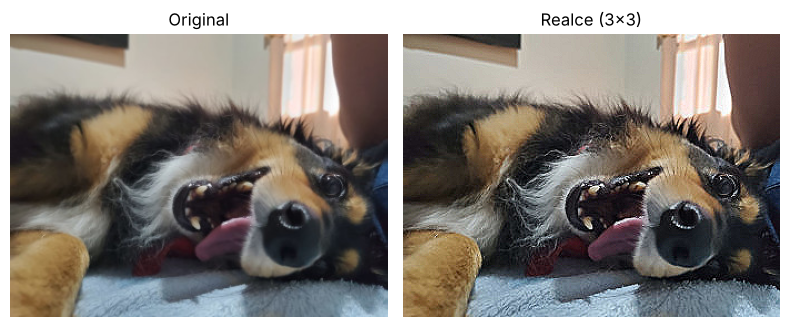

In [7]:
k_realce = np.array([[ 0, -1,  0],   # tira o vizinho de cima
                     [-1,  5, -1],   # 5x o pixel central, tira os vizinhos da esquerda e da direita
                     [ 0, -1,  0]])  # tira o vizinho de baixo
mostra([imagem, filtra(imagem, k_realce)],  # original e filtrada lado a lado
       ['Original', 'Realce (3x3)'])        # títulos

## 4. Filtro de média: kernel maior

O kernel de média é uma matriz N×N com todos os valores iguais a **1/N²** (soma = 1).
Cada pixel vira a média dos pixels ao redor, e a imagem fica **borrada**.

**Kernel maior** = média de mais pixels = imagem **mais borrada**: os detalhes menores que o kernel desaparecem.

In [8]:
def kernel_media(N):              # cria um kernel de média N x N
    return np.ones((N, N)) / N**2  # N² valores iguais a 1/N², então a soma é 1

print(kernel_media(3))            # exemplo: kernel 3x3, todos os valores = 1/9 ≈ 0,111

[[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]]


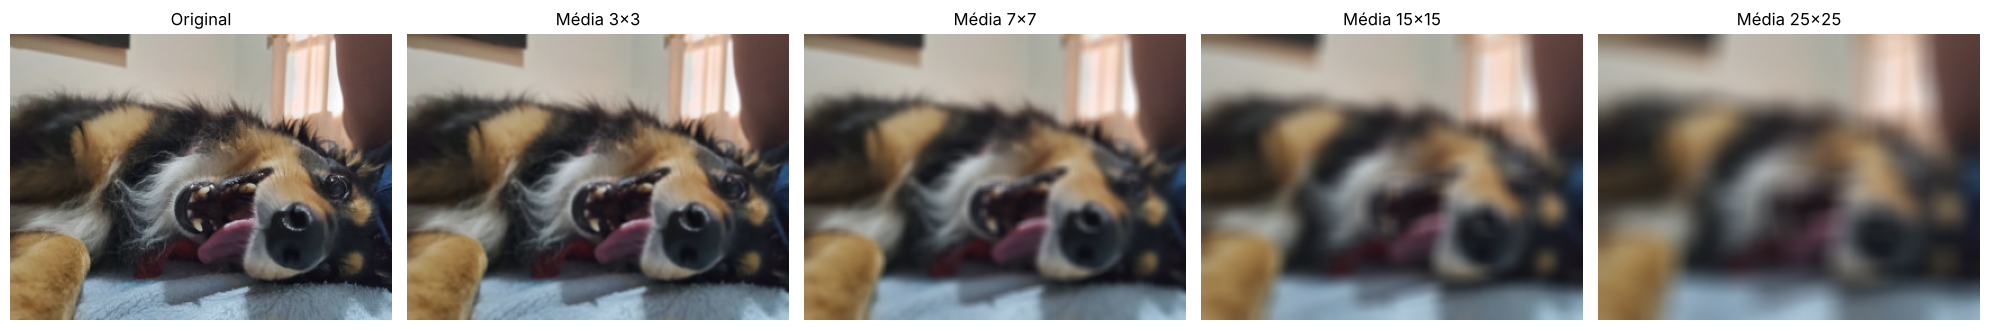

In [9]:
tamanhos = [3, 7, 15, 25]                                   # tamanhos de kernel a testar (ímpares)
filtradas = [filtra(imagem, kernel_media(N)) for N in tamanhos]  # filtra a imagem com cada tamanho
mostra([imagem] + filtradas,                                 # original + as 4 filtradas
       ['Original'] + [f'Média {N}x{N}' for N in tamanhos])  # títulos

## 5. Detecção de bordas

O kernel abaixo soma **8×** o pixel central e subtrai os 8 vizinhos. A soma dos pesos é **0**:
regiões uniformes ficam **pretas** (0) e só os contornos, onde o pixel difere dos vizinhos, aparecem.

O curso também pede, como exercício, **bordas verticais e horizontais**. Para isso usamos o kernel de **Sobel**:
ele compara a coluna da esquerda com a da direita (bordas verticais) ou a linha de cima com a de baixo
(bordas horizontais). Como a borda pode ser "claro→escuro" ou "escuro→claro", usamos o **valor absoluto**.

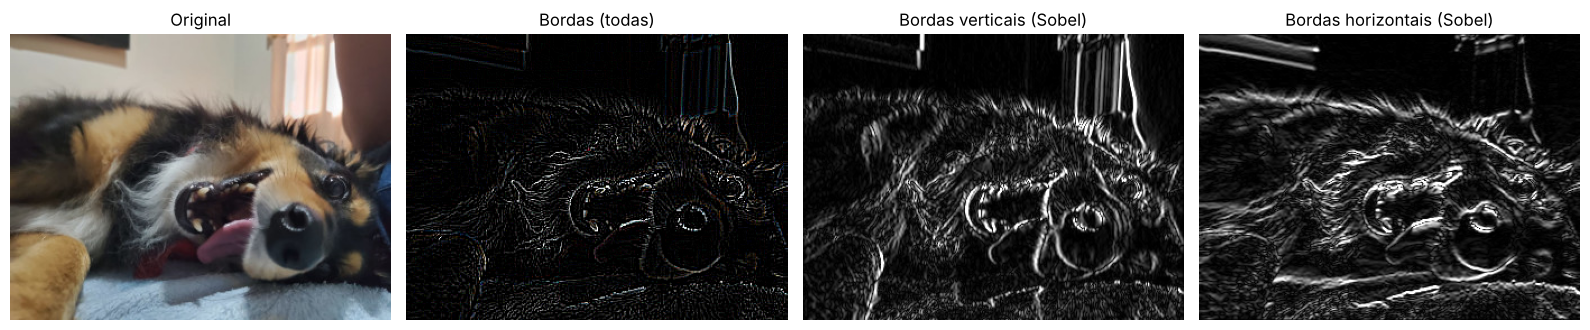

In [10]:
k_bordas = np.array([[-1, -1, -1],   # tira os 3 vizinhos de cima
                     [-1,  8, -1],   # 8x o centro, tira os vizinhos da esquerda e da direita
                     [-1, -1, -1]])  # tira os 3 vizinhos de baixo (soma = 0)

k_vertical = np.array([[-1, 0, 1],    # Sobel: coluna da direita menos coluna da esquerda
                       [-2, 0, 2],    # a linha do meio pesa 2x (mais perto do centro)
                       [-1, 0, 1]])   # detecta mudanças na horizontal = bordas VERTICAIS
k_horizontal = k_vertical.T          # transposta: linha de baixo menos linha de cima = bordas HORIZONTAIS

cinza = imagem.mean(axis=2)          # converte para tons de cinza (média dos 3 canais)
bv = np.abs(signal.convolve2d(cinza, k_vertical, boundary='symm', mode='same'))    # bordas verticais
bh = np.abs(signal.convolve2d(cinza, k_horizontal, boundary='symm', mode='same'))  # bordas horizontais

fig, axs = plt.subplots(1, 4, figsize=(16, 4))                    # 4 imagens lado a lado
axs[0].imshow(imagem); axs[0].set_title('Original')              # original
axs[1].imshow(filtra(imagem, k_bordas)); axs[1].set_title('Bordas (todas)')  # kernel 8 / -1
axs[2].imshow(bv, cmap='gray', vmax=np.percentile(bv, 99)); axs[2].set_title('Bordas verticais (Sobel)')    # Sobel vertical (vmax: realça as bordas fracas)
axs[3].imshow(bh, cmap='gray', vmax=np.percentile(bh, 99)); axs[3].set_title('Bordas horizontais (Sobel)')  # Sobel horizontal
for ax in axs: ax.axis('off')        # esconde os eixos de todas
plt.tight_layout()                   # ajusta os espaços
plt.show()                           # exibe a figura

## 6. Suavização gaussiana: kernel maior

O kernel gaussiano 2D tem a forma de um **sino**: peso máximo no centro e pesos cada vez menores
nas bordas do kernel. Ele é montado multiplicando um vetor gaussiano 1D (coluna) por ele mesmo (linha):

$$G[m,n] = g[m]\,g[n], \qquad g[x] = e^{-x^2/(2\sigma^2)}$$

Depois, como na média, os pesos são **normalizados para soma 1**.

Uso **σ = N/6** para que o sino ocupe o kernel inteiro (quase todo o peso fica dentro de ±3σ).
Assim, kernel maior também significa sino mais largo e mais suavização.

[[0.003 0.013 0.022 0.013 0.003]
 [0.013 0.06  0.098 0.06  0.013]
 [0.022 0.098 0.162 0.098 0.022]
 [0.013 0.06  0.098 0.06  0.013]
 [0.003 0.013 0.022 0.013 0.003]]


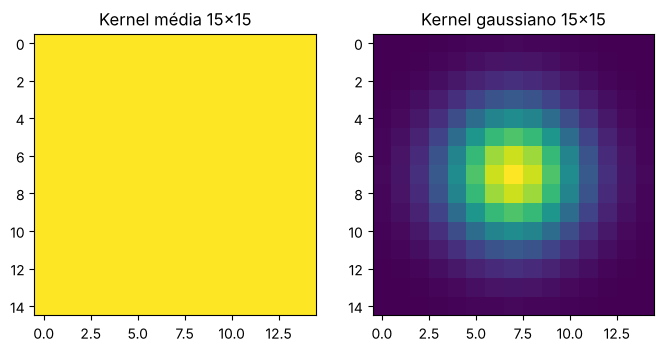

In [11]:
def kernel_gaussiano(N, sigma):                 # cria um kernel gaussiano N x N
    g = signal.windows.gaussian(N, sigma)       # vetor 1D com a curva gaussiana (máximo 1 no centro)
    G = np.outer(g, g)                          # produto coluna x linha: matriz N x N em forma de sino
    return G / G.sum()                          # normaliza para soma 1 (não muda o brilho da imagem)

print(np.round(kernel_gaussiano(5, 1), 3))      # exemplo 5x5 com σ=1: maior no centro, menor nas pontas

N = 15                                          # tamanho para visualizar o formato dos kernels
fig, axs = plt.subplots(1, 2, figsize=(8, 4))  # dois gráficos lado a lado
axs[0].imshow(kernel_media(N), cmap='viridis', vmin=0)  # kernel de média: tudo da mesma cor (pesos iguais)
axs[0].set_title(f'Kernel média {N}x{N}')      # título
axs[1].imshow(kernel_gaussiano(N, N / 6), cmap='viridis', vmin=0)  # kernel gaussiano: claro no centro
axs[1].set_title(f'Kernel gaussiano {N}x{N}')  # título
plt.show()                                     # exibe a figura

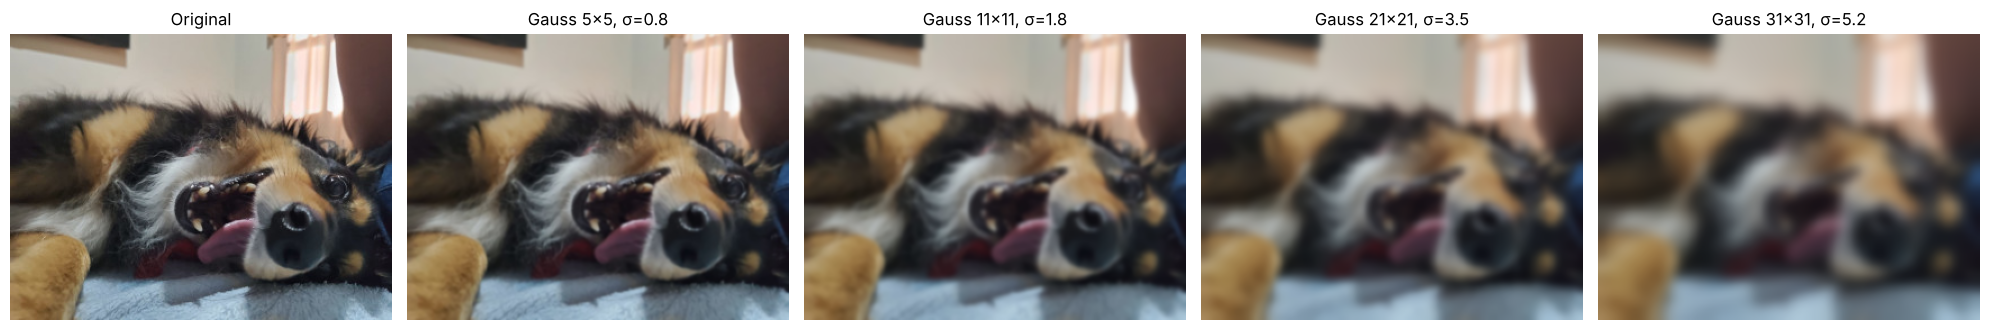

In [12]:
tamanhos = [5, 11, 21, 31]                                          # tamanhos de kernel a testar
filtradas = [filtra(imagem, kernel_gaussiano(N, N / 6)) for N in tamanhos]  # σ = N/6 para cada tamanho
mostra([imagem] + filtradas,                                        # original + as filtradas
       ['Original'] + [f'Gauss {N}x{N}, σ={N/6:.1f}' for N in tamanhos])  # títulos

### Média x gaussiano com o mesmo tamanho

Com o **mesmo tamanho** de kernel, a média borra mais,
porque dá o mesmo peso a pixels distantes. A gaussiana dá menos peso a eles e o desfoque fica mais **suave e natural**.
O recorte ampliado (zoom) deixa a diferença mais visível.

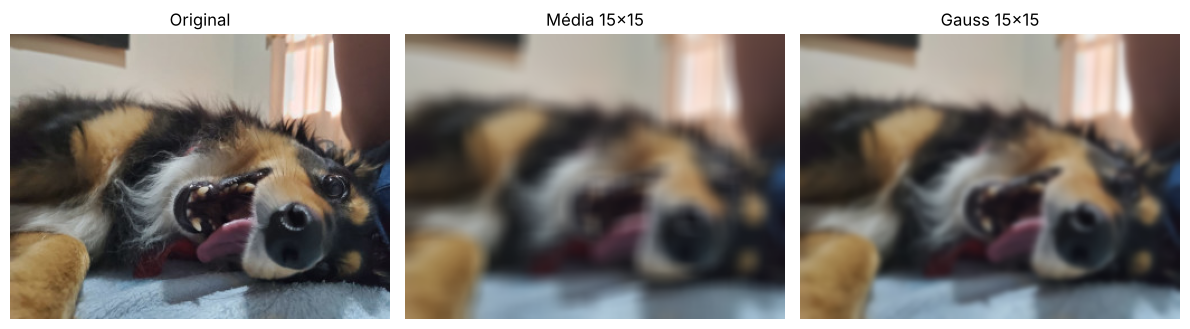

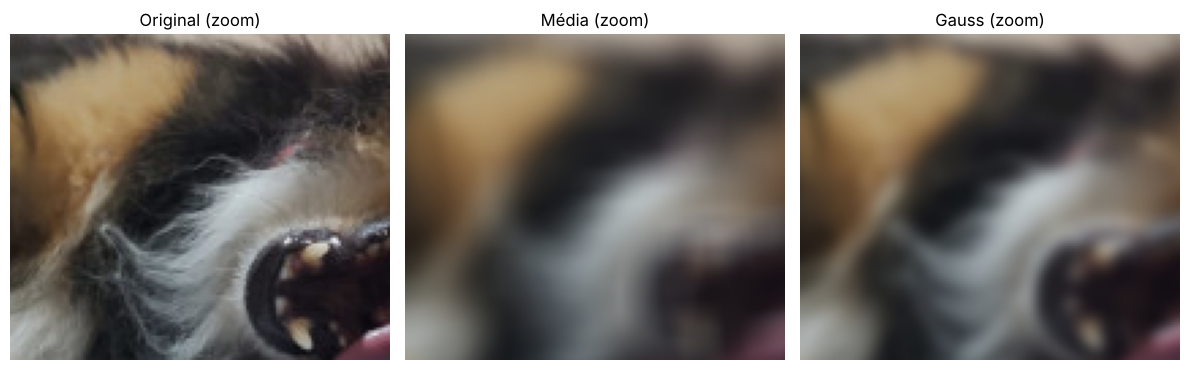

In [13]:
N = 15                                                 # mesmo tamanho para os dois kernels
img_media = filtra(imagem, kernel_media(N))            # imagem filtrada pela média
img_gauss = filtra(imagem, kernel_gaussiano(N, N / 6))  # imagem filtrada pela gaussiana
mostra([imagem, img_media, img_gauss],                 # imagens inteiras
       ['Original', f'Média {N}x{N}', f'Gauss {N}x{N}'])

r = (slice(60, 180), slice(60, 200))                   # recorte (linhas 60-180, colunas 60-200) para dar zoom
mostra([imagem[r], img_media[r], img_gauss[r]],        # mesmos recortes das três imagens
       ['Original (zoom)', 'Média (zoom)', 'Gauss (zoom)'])

## 7. Convolução em vídeo (opcional, precisa de webcam)

O mesmo filtro pode ser aplicado em cada quadro da câmera. Para rodar no seu computador:
instale o OpenCV (`pip install opencv-python`) e mude `USAR_CAMERA` para `True`. Aperte **q** para sair.

In [14]:
USAR_CAMERA = False                                 # mude para True para usar a webcam

if USAR_CAMERA:                                     # só executa se a câmera estiver habilitada
    import cv2                                      # OpenCV: captura e exibição de vídeo
    camera = cv2.VideoCapture(0)                    # abre a webcam padrão (índice 0)
    kernel = kernel_gaussiano(11, 11 / 6)           # escolha aqui o kernel (média, gaussiano, bordas...)
    while True:                                     # repete para cada quadro do vídeo
        ok, frame = camera.read()                   # lê um quadro da câmera
        if not ok:                                  # se não conseguiu ler, encerra
            break
        frame = cv2.resize(frame, (500, 400))       # reduz o quadro para a convolução ser mais rápida
        cv2.imshow('Camera filtrada', filtra(frame, kernel))  # aplica o filtro e mostra o resultado
        if cv2.waitKey(1) & 0xFF == ord('q'):       # sai do laço quando a tecla q é apertada
            break
    camera.release()                                # libera a câmera
    cv2.destroyAllWindows()                         # fecha a janela

## Conclusões

- A **convolução 2D** é a mesma operação da 1D, mas com uma matriz como kernel deslizando nas duas direções.
- O **kernel define o efeito**:
  - soma = 1 (média, gaussiano, realce) mantém o brilho;
  - soma = 0 (bordas) apaga as regiões uniformes e deixa só os contornos.
- **Kernel maior** = cada pixel é influenciado por uma região maior = **mais borrado**, e a conta fica mais lenta
  (N² multiplicações por pixel).
- Com o mesmo tamanho, o **gaussiano** borra de forma mais suave e natural que a **média**, porque dá menos peso aos pixels distantes.